# A simple symbolic regression example

This notebook implements a **symbolic regression pipeline** based on **Genetic Programming (GP)** using the `flex` framework and its custom `GPSymbolicRegressor`.

The goal is to discover analytical expressions that best fit a given `PMLB` dataset by:
- evolving symbolic expressions;
- optimizing embedded numerical constants;
- penalizing overly complex expressions;
- evaluating performance on training and test datasets.

The code supports:
- multi-variable regression problems;
- automatic constant tuning using gradient-based optimization;
- parallel execution using Ray.

## Imports and Dependencies

First, we import all the required libraries for:

- **Genetic Programming**: `deap.gp`, custom `flex.gp` utilities
- **Numerical computation**: `numpy`
- **Tree evaluation and constant fitting**: `flex.gp.numba_eval` (numba-compiled interpreter, Levenberg-Marquardt)
- **Machine Learning utilities**: `scikit-learn`
- **Parallelism**: `ray`
- **Dataset generation**: custom `generate_dataset` function

The code relies on both evolutionary optimization (for structure) and gradient-based optimization (for constants).

In [1]:
%env RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0

env: RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0


In [2]:
from deap import gp

from flex.gp import regressor as gps
from flex.gp.util import (
    get_features_batch,
    load_config_data,
)
from flex.gp.numba_eval import assign_attributes, fit_mse, predict_batch, score_batch
from flex.gp.primitives import add_primitives_to_pset_from_dict
import numpy as np
import ray

from sklearn.metrics import r2_score

import time


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from pmlb import fetch_data

import matplotlib.pyplot as plt

In [3]:
# set up number of cpus per ray worker
num_cpus = 1

In [4]:
# --- Custom generate dataset function ---
def generate_dataset(problem: str="1027_ESL", random_state: int=42, scaleXy: bool=True):
    np.random.seed(42)
    num_variables = 1
    scaler_X = None
    scaler_y = None

    # PMLB datasets
    X, y = fetch_data(problem, return_X_y=True, local_cache_dir="./datasets")

    num_variables = X.shape[1]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=random_state
    )

    y_train = y_train.reshape(-1, 1)
    y_test = y_test.reshape(-1, 1)

    if scaleXy:
        scaler_X = StandardScaler()
        scaler_y = StandardScaler()

        X_train_scaled = scaler_X.fit_transform(X_train)
        y_train_scaled = scaler_y.fit_transform(y_train)
        X_test_scaled = scaler_X.transform(X_test)
    else:
        X_train_scaled = X_train
        y_train_scaled = y_train
        X_test_scaled = X_test

    y_test = y_test.flatten()
    y_train_scaled = y_train_scaled.flatten()

    num_train_points = X_train.shape[0]


    # note y_test and y_train_scaled must be flattened
    return (
        X_train_scaled,
        y_train_scaled,
        X_test_scaled,
        y_test,
        scaler_X,
        scaler_y,
        num_variables,
        num_train_points,
    )

## Evaluation Function and Constant Optimization

The core of the symbolic regression pipeline is the definition of the fitness function. First, we need to define an error measure, which in this case will be the standard MSE between the targets and the predictions.
However, we remark that each individual carries some numerical constants that need to be optimized as well. For example, the individual
$$I(x) = c_1\sin(x) + c_2x^2 + c_3$$
may have a near 0 fitness for a given triple $(c_1, c_2, c_3)$ and a very large fitness for other triples. This simple examples shows that it is important to auto-optimize carefully the constants in each individual.

If the evaluation function is differentiable, then one natural choice to auto-optimize constants is the use of any gradient-based solver. In this example, we use `fit_mse` of `flex.gp.numba_eval`: it evaluates the tree with a numba-compiled interpreter and fits the constants (starting from random values, within [-5, 5]) by minimizing the MSE with the Levenberg-Marquardt method, using the exact derivatives of the tree with respect to the constants.

In [5]:
def eval_MSE_and_tune_constants(tree, toolbox, X, y):
    MSE, consts = fit_mse(tree, toolbox.compile.keywords["pset"], X, y)
    if np.isinf(MSE) or np.isnan(MSE):
        MSE = 1e8
    return MSE, consts

## Expression Complexity and Structure Checks

The function `get_features_batch` of `flex.gp.util` computes, for each individual:
- its length (number of nodes);
- whether it contains nested trigonometric functions (a sin/cos node with another one in its subtree);
- its number of trigonometric functions.

They are later used to regularize the fitness function.

## Fitness and Prediction Functions

The fitness function combines:
- prediction error (MSE),
- structural penalties (expression length),
- functional penalties (nested trigonometric functions).

A **Tarpeian selection** strategy is applied to discard very large trees early.

The predictions, the score (MSE) and the storage of the fitness and of the fitted constants on the individuals use `predict_batch`, `score_batch` and `assign_attributes` of `flex.gp.numba_eval`.

In [6]:
def compute_attributes(individuals_batch, toolbox, X, y, penalty, fitness_scale):

    attributes = [None] * len(individuals_batch)

    individ_length, nested_trigs, num_trigs = get_features_batch(individuals_batch)

    for i, tree in enumerate(individuals_batch):

        # Tarpeian selection
        if individ_length[i] >= 50:
            consts = None
            fitness = (1e8,)
        else:
            MSE, consts = eval_MSE_and_tune_constants(tree, toolbox, X, y)
            fitness = (
                fitness_scale
                * (
                    MSE
                    + 100000 * nested_trigs[i]
                    + 0.0 * num_trigs[i]
                    + penalty["reg_param"] * individ_length[i]
                ),
            )
        attributes[i] = {"consts": consts, "fitness": fitness}
    return attributes

## Main Training and Evaluation Pipeline

The following cell orchestrates the entire symbolic regression process:
1. loads configuration from a YAML file;
2. generates training and test datasets;
3. builds the GP primitive set;
4. initializes the symbolic regressor;
5. trains the model;
6. evaluates performance on training and test sets.

In [7]:
regressor_params, config_file_data = load_config_data("simple_sr.yaml")

scaleXy = config_file_data["gp"]["scaleXy"]

# generate training and test datasets
(
    X_train_scaled,
    y_train_scaled,
    X_test_scaled,
    y_test,
    _,
    scaler_y,
    num_variables,
    _,
) = generate_dataset("1096_FacultySalaries", scaleXy=scaleXy, random_state=29802)

if num_variables == 1:
    pset = gp.PrimitiveSetTyped("Main", [float], float)
    pset.renameArguments(ARG0="x")
elif num_variables == 2:
    pset = gp.PrimitiveSetTyped("Main", [float, float], float)
    pset.renameArguments(ARG0="x")
    pset.renameArguments(ARG1="y")
else:
    pset = gp.PrimitiveSetTyped("Main", [float] * num_variables, float)

pset = add_primitives_to_pset_from_dict(pset, config_file_data["gp"]["primitives"])

batch_size = config_file_data["gp"]["batch_size"]
if config_file_data["gp"]["use_constants"]:
    pset.addTerminal(object, float, "c")

callback_func = assign_attributes
fitness_scale = 1.0

penalty = config_file_data["gp"]["penalty"]
common_params = {"penalty": penalty, "fitness_scale": fitness_scale}

gpsr = gps.GPSymbolicRegressor(
    pset_config=pset,
    fitness=compute_attributes,
    predict_func=predict_batch,
    score_func=score_batch,
    common_data=common_params,
    callback_func=callback_func,
    print_log=True,
    num_best_inds_str=1,
    save_best_individual=False,
    output_path="./",
    seed_str=None,
    batch_size=batch_size,
    num_cpus=num_cpus,
    remove_init_duplicates=True,
    **regressor_params,
)

tic = time.time()
gpsr.fit(X_train_scaled, y_train_scaled)
toc = time.time()

best = gpsr.get_best_individuals(n_ind=1)[0]

if hasattr(best, "consts"):
    print("Best parameters = ", best.consts)

print("Elapsed time = ", toc - tic)
individuals_per_sec = (
    (gpsr.get_last_gen() + 1)
    * gpsr.num_individuals
    * gpsr.num_islands
    / (toc - tic)
)
print("Individuals per sec = ", individuals_per_sec)

u_best = gpsr.predict(X_test_scaled)

# de-scale outputs before computing errors
if scaleXy:
    u_best = scaler_y.inverse_transform(u_best.reshape(-1, 1)).flatten()

MSE = np.mean((u_best - y_test) ** 2)
r2_test = r2_score(y_test, u_best)
print("MSE on the test set = ", MSE)
print("R^2 on the test set = ", r2_test)

pred_train = gpsr.predict(X_train_scaled)

if scaleXy:
    pred_train = scaler_y.inverse_transform(pred_train.reshape(-1, 1)).flatten()
    y_train_scaled = scaler_y.inverse_transform(
        y_train_scaled.reshape(-1, 1)
    ).flatten()

MSE = np.mean((pred_train - y_train_scaled) ** 2)
r2_train = r2_score(y_train_scaled, pred_train)
print("MSE on the training set = ", MSE)
print("R^2 on the training set = ", r2_train)

# ray is explicitly shut down at the end of the execution to release computational resources
ray.shutdown()

2026-11-24 17:32:26,917	INFO worker.py:1841 -- Started a local Ray instance.


Generating initial population(s)...


 Removing duplicates from initial population(s)...


 DONE.


DONE.


Evaluating initial population(s)...


... (63 outputs left out)

The best individual is aq(add(sin(sub(ARG1, ARG2)), ARG1), sin(add(sub(c, ARG2), aq(ARG1, c))))


The best fitness on the training set is 0.1024


Best parameters =  [ 3.50892348 -0.68332615]
Elapsed time =  11.404615640640259
Individuals per sec =  3682.7194640679804


MSE on the test set =  1.3762064211285003
R^2 on the test set =  0.8174563788931077
MSE on the training set =  2.2330511555697585
R^2 on the training set =  0.9125853633525719


In [8]:
# get the sympy version of the best individual
best_expression_sympy_str = str(gpsr.get_best_individuals_sympy()[0])
best_expression_sympy_str

'(ARG1 + sin(ARG1 - ARG2))/sqrt(sin(0.8256474026350168*ARG1 - ARG2 + 3.5089234768676714)**2 + 1)'

## Plots

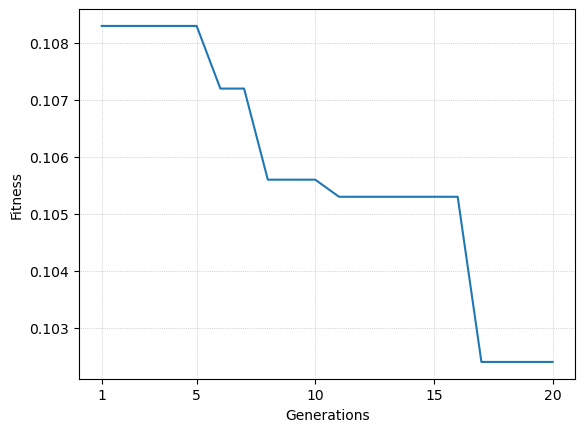

In [9]:
fitness = gpsr.get_train_fit_history()
generations = gpsr.generations
plt.plot(np.arange(1, generations+1), fitness)
plt.xlabel("Generations")
plt.ylabel("Fitness")
plt.xticks([1, 5, 10, 15, 20])
plt.grid(True, linestyle=":", linewidth=0.5)
plt.show()

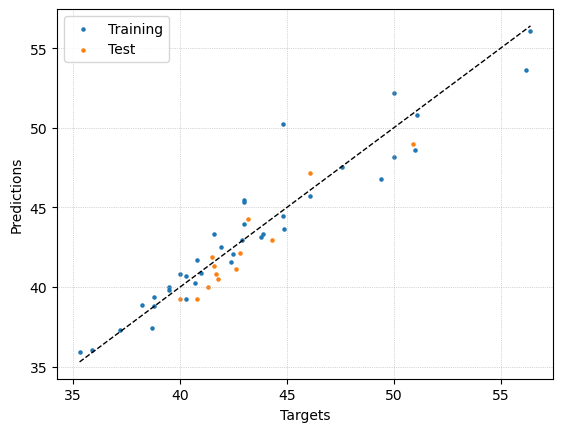

In [10]:
y_min = min(np.min(y_train_scaled), np.min(y_test))
y_max = max(np.max(y_train_scaled), np.max(y_test))

plt.scatter(y_train_scaled, pred_train, s=5, label="Training")
plt.scatter(y_test, u_best, s=5, label="Test")
plt.plot([y_min, y_max], [y_min, y_max], "k--", linewidth=1)
plt.grid(True, linestyle=":", linewidth=0.5)
plt.xlabel("Targets")
plt.ylabel("Predictions")
plt.legend()
plt.show()